# ERA5 against five CMIP6 models over Europe

This notebook compares near-surface air temperature from five CMIP6 historical
simulations with the ERA5 reanalysis over Europe (35N to 72N, 10W to 40E) for
1995 to 2014, by season. Both datasets are read anonymously from public cloud
storage: ERA5 from Google's ARCO-ERA5 Zarr store, the models from the Pangeo
CMIP6 catalogue through intake-esm. Nothing needs credentials.

What climval does here:

- puts each of five models, with three different calendars (`noleap`,
  `proleptic_gregorian`, `360_day`) and five different grids, on a common grid
  with ERA5 and on common months;
- scores each model in one `climval.compare` call and collects the five
  results in one table;
- computes the statistics of a Taylor diagram for the seasonal climatology and
  records every alignment step.

About 560 MB are read from the cloud. The run takes a few minutes on a laptop.

## Setup

In [1]:
import warnings

import dask
import gcsfs
import intake
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import climval

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Consolidated metadata.*")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

fs = gcsfs.GCSFileSystem(token="anon")
print("climval", climval.__version__, "| xarray", xr.__version__, "| dask", dask.__version__)

climval 0.2.0 | xarray 2026.9.0 | dask 2026.8.0


In [2]:
PERIOD = ("1995", "2014")
EUROPE = climval.Box(lat=(35, 72), lon=(-10, 40), name="Europe")

## ERA5 from ARCO-ERA5

ARCO-ERA5 has no monthly-mean store. The smallest store with near-surface
temperature is ERA5 conservatively regridded to 1.5 degrees, every 6 hours,
with chunks of 8 time steps (two days) over the whole globe. Reading every
chunk for 20 years would be about 2.2 GB, so this notebook reads one chunk in
six: two consecutive days, with all four analyses (00, 06, 12 and 18 UTC),
every twelve days. Monthly means are then estimated from the sampled days.
The cost of this saving is sampling noise, which is estimated below.

In [3]:
ERA5_STORE = (
    "gcp-public-data-arco-era5/ar/1959-2022-6h-240x121_equiangular_with_poles_conservative.zarr"
)
era5 = xr.open_zarr("gs://" + ERA5_STORE, storage_options={"token": "anon"}, chunks={})
t2m = era5["2m_temperature"]
print(t2m.dims, t2m.shape, "chunks", t2m.encoding["chunks"], "units", t2m.attrs.get("units"))
print("time", str(era5.time.values[0])[:16], "to", str(era5.time.values[-1])[:16])

('time', 'longitude', 'latitude') (92040, 240, 121) chunks (8, 240, 121) units K
time 1959-01-02T00:00 to 2021-12-31T18:00


In [4]:
EVERY = 6  # read one two-day chunk in six
step = t2m.encoding["chunks"][0]
times = pd.DatetimeIndex(era5.time.values)
i0 = int(np.searchsorted(times, np.datetime64(f"{PERIOD[0]}-01-01")))
i1 = int(np.searchsorted(times, np.datetime64(f"{int(PERIOD[1]) + 1}-01-01")))
blocks = [k for k in range(-(-i0 // step), i1 // step) if k % EVERY == 0]
index = np.concatenate([np.arange(k * step, (k + 1) * step) for k in blocks])

sizes = {
    f["name"].rsplit("/", 1)[-1]: f["size"]
    for f in fs.ls(ERA5_STORE + "/2m_temperature", detail=True)
}
era5_bytes = sum(sizes[f"{k}.0.0"] for k in blocks)
print(f"{len(blocks)} chunks of {step} time steps, {times[index[0]]} to {times[index[-1]]}")
print(f"ERA5 bytes to read: {era5_bytes / 1e6:.0f} MB")

609 chunks of 8 time steps, 1995-01-05 00:00:00 to 2014-12-28 18:00:00
ERA5 bytes to read: 374 MB


In [5]:
# Only the European part of each global chunk is kept, with a margin of two
# cells around the box. climval keeps a one-cell margin of the grid it
# interpolates, so the points at the edge of the box have neighbours.
sub = t2m.isel(time=index)
sub = sub.assign_coords(longitude=((sub.longitude + 180) % 360) - 180).sortby("longitude")
sub = sub.sel(latitude=slice(33, 75), longitude=slice(-13, 43)).transpose(
    "time", "latitude", "longitude"
)
with dask.config.set(scheduler="threads", num_workers=8):
    sub = sub.load()
print(sub.shape, f"{sub.nbytes / 1e6:.0f} MB in memory")

(4872, 28, 37) 20 MB in memory


In [6]:
era5_monthly = sub.resample(time="MS").mean().rename("t2m")
era5_monthly.attrs = {"units": "K", "long_name": "2 m temperature, monthly mean of sampled days"}
days = sub.time.dt.floor("D").to_series().groupby(pd.Grouper(freq="MS")).nunique()
print(
    f"{era5_monthly.sizes['time']} months; sampled days per month: "
    f"min {days.min()}, max {days.max()}, mean {days.mean():.1f}"
)

240 months; sampled days per month: min 4, max 6, mean 5.1


### How large is the sampling noise?

Each two-day chunk gives one block mean. For each season and grid point the
standard error of the 20-year seasonal mean is estimated as the standard
deviation of the block means divided by the square root of their number. The
blocks are twelve days apart, so they are treated as independent. The spread
also contains the seasonal cycle within each season, so this is an upper
estimate. Only blocks in the seasons the comparison below scores are
counted: January and February 1995 and December 2014 belong to incomplete
winters, which the comparison leaves out.

In [7]:
block_means = sub.coarsen(time=step).mean()
year, month = block_means.time.dt.year, block_means.time.dt.month
incomplete_winter = ((year == 1995) & (month <= 2)) | ((year == 2014) & (month == 12))
block_means = block_means.isel(time=np.nonzero(~incomplete_winter.values)[0])
by_season = block_means.groupby("time.season")
stderr = by_season.std("time", ddof=1) / np.sqrt(by_season.count("time"))
table = pd.DataFrame(
    {
        "blocks": by_season.count("time").isel(latitude=0, longitude=0).to_series(),
        "median standard error (K)": stderr.median(["latitude", "longitude"]).to_series(),
        "largest standard error (K)": stderr.max(["latitude", "longitude"]).to_series(),
    }
).loc[["DJF", "MAM", "JJA", "SON"]]
table

,blocks,median standard error (K),largest standard error (K)
season,,,
DJF,144,0.278,0.673
MAM,153,0.320,0.686
JJA,153,0.192,0.346
SON,151,0.345,0.617


These errors apply to the seasonal climatology. A single monthly mean rests on
about five sampled days and is far noisier, so this notebook reads the
climatology sample, not month-by-month values.

## CMIP6 models from the Pangeo catalogue

In [8]:
cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
MEMBERS = {
    "CanESM5": "r1i1p1f1",
    "IPSL-CM6A-LR": "r1i1p1f1",
    "MPI-ESM1-2-LR": "r1i1p1f1",
    "NorESM2-LM": "r1i1p1f1",
    "UKESM1-0-LL": "r1i1p1f2",
}
query = cat.search(
    experiment_id="historical",
    table_id="Amon",
    variable_id="tas",
    source_id=list(MEMBERS),
    member_id=sorted(set(MEMBERS.values())),
)
rows = query.df[
    [MEMBERS[s] == m for s, m in zip(query.df.source_id, query.df.member_id, strict=True)]
]
rows[["source_id", "institution_id", "member_id", "grid_label", "version", "zstore"]]

,source_id,institution_id,member_id,grid_label,version,zstore
0,IPSL-CM6A-LR,IPSL,r1i1p1f1,gr,20180803,gs://cmip6/CMIP6/CMIP/IPSL/IPSL-CM6A-LR/histor...
1,UKESM1-0-LL,MOHC,r1i1p1f2,gn,20190406,gs://cmip6/CMIP6/CMIP/MOHC/UKESM1-0-LL/histori...
2,CanESM5,CCCma,r1i1p1f1,gn,20190429,gs://cmip6/CMIP6/CMIP/CCCma/CanESM5/historical...
3,MPI-ESM1-2-LR,MPI-M,r1i1p1f1,gn,20190710,gs://cmip6/CMIP6/CMIP/MPI-M/MPI-ESM1-2-LR/hist...
4,NorESM2-LM,NCC,r1i1p1f1,gn,20190815,gs://cmip6/CMIP6/CMIP/NCC/NorESM2-LM/historica...


In [9]:
dsets = query.to_dataset_dict(
    xarray_open_kwargs={"consolidated": True, "chunks": {}},
    storage_options={"token": "anon"},
    progressbar=False,
)
models = {}
for ds in dsets.values():
    source = ds.attrs["source_id"]
    models[source] = ds["tas"].sel(member_id=MEMBERS[source]).squeeze(drop=True)
models = dict(sorted(models.items()))


def bytes_for_period(row, period):
    """Bytes of the stored chunks that hold the period (whole global chunks)."""
    store = row.zstore.replace("gs://", "").rstrip("/") + "/tas"
    chunk = xr.open_zarr(row.zstore, storage_options={"token": "anon"})["tas"].encoding["chunks"][0]
    years = models[row.source_id].time.dt.year.values
    idx = np.nonzero((years >= int(period[0])) & (years <= int(period[1])))[0]
    files = {f["name"].rsplit("/", 1)[-1]: f["size"] for f in fs.ls(store, detail=True)}
    return sum(files[f"{c}.0.0"] for c in np.unique(idx // chunk))


info = pd.DataFrame(
    {
        "institution_id": rows.set_index("source_id").institution_id,
        "member_id": rows.set_index("source_id").member_id,
        "grid (lat x lon)": {
            s: f"{da.sizes['lat']} x {da.sizes['lon']}" for s, da in models.items()
        },
        "calendar": {s: da.time.dt.calendar for s, da in models.items()},
        "MB to read": {r.source_id: bytes_for_period(r, PERIOD) / 1e6 for r in rows.itertuples()},
    }
).sort_index()
print(
    f"CMIP6 bytes to read: {info['MB to read'].sum():.0f} MB; "
    f"total with ERA5: {(info['MB to read'].sum() + era5_bytes / 1e6):.0f} MB"
)
info.round(1)

CMIP6 bytes to read: 185 MB; total with ERA5: 559 MB


,institution_id,member_id,grid (lat x lon),calendar,MB to read
CanESM5,CCCma,r1i1p1f1,64 x 128,noleap,16.4
IPSL-CM6A-LR,IPSL,r1i1p1f1,143 x 144,proleptic_gregorian,40.7
MPI-ESM1-2-LR,MPI-M,r1i1p1f1,96 x 192,proleptic_gregorian,39.7
NorESM2-LM,NCC,r1i1p1f1,96 x 144,noleap,34.2
UKESM1-0-LL,MOHC,r1i1p1f2,144 x 192,360_day,53.9


## Compare each model with ERA5

Each model is compared on the coarser of its own grid and the 1.5 degree
ERA5 grid, climval's default (`target="coarser"`), so no model is
interpolated to a finer grid than it has. climval compares the cell size as
latitude spacing times longitude spacing: every model cell is larger than
an ERA5 cell by that measure, although IPSL-CM6A-LR (about 1.27 degrees) and
UKESM1-0-LL (1.25 degrees) are finer than ERA5 in latitude. So ERA5 is
interpolated bilinearly onto each model grid. Where a model grid is more
than 1.5 times coarser than ERA5 along latitude or longitude (CanESM5,
IPSL-CM6A-LR and NorESM2-LM here), climval warns that bilinear interpolation
samples ERA5 at the model points instead of averaging it over the model
cells; the limits at the end come back to this.

One `climval.compare` call per model cuts both inputs to the box, matches
the months by year and month (so a `360_day` or `noleap` month meets the same
calendar month of ERA5), regrids, checks units and computes every metric in
one dask pass. With `by="season"` the seasons are contiguous: a December
counts in the following winter, so DJF holds the 19 complete winters from
December 1995 to February 2014. The `time` sample adds per-grid-point maps.

In [10]:
results = {}
caught = {}
for source, tas in models.items():
    with (
        warnings.catch_warnings(record=True) as warned,
        dask.config.set(scheduler="threads", num_workers=4),
    ):
        warnings.simplefilter("always", UserWarning)
        results[source] = climval.compare(
            era5_monthly,
            tas,
            region=EUROPE,
            period=PERIOD,
            by="season",
            names=("ERA5", source),
            samples=("space_time", "climatology", "time"),
        )
    for w in warned:
        if issubclass(w.category, UserWarning):
            caught.setdefault(str(w.message), []).append(source)
for message, sources in caught.items():
    print(f"climval warned for {', '.join(sources)}:")
    print(f"  {message}")


def step_record(result, name):
    return next(s for s in result.provenance["steps"] if s["step"] == name)


overview = {}
for source, res in results.items():
    t, grid = step_record(res, "time"), step_record(res, "target_grid")
    ref = res.aligned.reference
    overview[source] = {
        "calendars": f"{t['calendars']['reference']} / {t['calendars']['candidate']}",
        "matched months": t["matched_periods"],
        "range": " to ".join(r[:7] for r in t["range"]),
        "comparison grid": grid["target"],
        "points in box (lat x lon)": f"{ref.sizes['lat']} x {ref.sizes['lon']}",
    }
pd.DataFrame(overview).T

climval warned for CanESM5, IPSL-CM6A-LR, NorESM2-LM:
  The reference is regridded onto a coarser grid with bilinear, which samples it at the target points and does not average over the target cells. regrid='conservative' (xESMF) gives cell means.


,calendars,matched months,range,comparison grid,points in box (lat x lon)
CanESM5,proleptic_gregorian / noleap,240,1995-01 to 2014-12,candidate,13 x 18
IPSL-CM6A-LR,proleptic_gregorian / proleptic_gregorian,240,1995-01 to 2014-12,candidate,29 x 21
MPI-ESM1-2-LR,proleptic_gregorian / proleptic_gregorian,240,1995-01 to 2014-12,candidate,20 x 27
NorESM2-LM,proleptic_gregorian / noleap,240,1995-01 to 2014-12,candidate,20 x 21
UKESM1-0-LL,proleptic_gregorian / 360_day,240,1995-01 to 2014-12,candidate,30 x 26


In [11]:
for line in climval.result.describe_steps(results["UKESM1-0-LL"].provenance["steps"]):
    print(line)

inputs: reference_variable=t2m, candidate_variable=tas
coordinates: reference={...}, candidate={"grid": "rectilinear", "detected": {"lat": "lat", "lon": "lon", "time": "time"}, "changes": []}
target_grid: target=candidate, requested=coarser, regridded=["reference"]
longitude: frame=[-180.0, 180.0], reference=-180..180 unchanged, candidate=0..360 re-expressed in frame
region: region={"type": "box", "name": "Europe", "lat": [35, 72], "lon": [-10, 40], "crosses_antimeridian": false}, reference_points={"lat": 27, "lon": 35}, candidate_points={"lat": 30, "lon": 26}
time: calendars={"reference": "proleptic_gregorian", "candidate": "360_day"}, native_frequency={"reference": "monthly (from time steps)", "candidate": "monthly (from time steps)"}, period=["1995", "2014"], frequency=monthly, matched_periods=240, unmatched_dropped={"reference": 0, "candidate": 0}, method=periods matched by calendar labels (year-month), not by timestamp, range=["1995-01-01T00:00:00.000000000", "2014-12-01T00:00:00.

## Five models, one table

Each result's long table gets a `model` column, and the five are joined.

In [12]:
values = pd.concat(
    [res.to_dataframe().assign(model=source) for source, res in results.items()],
    ignore_index=True,
)
values.head()

,sample,group,metric,value,units,model
0,space_time,all,rmse,2.834,K,CanESM5
1,space_time,DJF,rmse,3.641,K,CanESM5
2,space_time,MAM,rmse,2.638,K,CanESM5
3,space_time,JJA,rmse,2.301,K,CanESM5
4,space_time,SON,rmse,2.625,K,CanESM5


## Taylor statistics of the seasonal climatology

The `climatology` sample compares the 20-year mean fields of each season over
space. The time means weight each month by its length in days, and the
spatial statistics weight each cell by its area, computed from the cell
bounds of the comparison grid. `pearson_r` is the pattern correlation,
`std_ratio` the ratio of spatial standard deviations (model over ERA5),
`crmse` the centred root mean square difference and `mean_bias` the
area-weighted mean difference, model minus ERA5.

In [13]:
clim = values[values["sample"] == "climatology"].pivot_table(
    index=["model", "group"], columns="metric", values="value"
)
seasons = ["DJF", "MAM", "JJA", "SON", "all"]
taylor = clim[["mean_bias", "rmse", "crmse", "pearson_r", "std_ratio"]].reindex(
    pd.MultiIndex.from_product([list(results), seasons], names=["model", "group"])
)
taylor.round(3)

metric               mean_bias   rmse  crmse  pearson_r  std_ratio
model         group                                               
CanESM5       DJF        0.690  1.443  1.267      0.983      1.067
              MAM        0.056  0.991  0.989      0.976      0.977
              JJA        0.477  1.202  1.104      0.985      1.134
              SON        0.395  1.131  1.060      0.982      1.072
              all        0.397  1.027  0.947      0.983      1.067
IPSL-CM6A-LR  DJF       -0.804  1.712  1.511      0.985      1.130
              MAM       -1.091  1.630  1.211      0.968      1.014
              JJA        0.734  1.701  1.534      0.952      0.922
              SON        0.423  1.159  1.079      0.981      1.029
              all       -0.193  1.153  1.136      0.975      1.032
MPI-ESM1-2-LR DJF       -0.144  1.323  1.315      0.983      1.076
              MAM       -0.662  1.291  1.108      0.972      1.009
              JJA       -0.159  1.465  1.457      0.962      1.066
              SON       -0.021  1.186  1.185      0.982      1.104
              all       -0.255  1.072  1.041      0.981      1.070
NorESM2-LM    DJF        1.706  2.336  1.595      0.972      0.995
              MAM        0.737  1.507  1.314      0.986      1.196
              JJA        0.310  1.736  1.708      0.976      1.228
              SON        0.726  1.532  1.349      0.976      1.087
              all        0.862  1.580  1.323      0.982      1.152
UKESM1-0-LL   DJF       -1.922  3.001  2.305      0.984      1.292
              MAM       -1.501  1.843  1.070      0.979      1.080
              JJA       -0.573  1.547  1.437      0.977      1.169
              SON       -0.457  1.128  1.031      0.989      1.112
              all       -1.129  1.668  1.228      0.987      1.173

In [14]:
annual = taylor.xs("all", level="group")
print("Annual-mean climatology (group 'all'):")
print(
    f"  pattern correlation from {annual.pearson_r.min():.3f} ({annual.pearson_r.idxmin()}) "
    f"to {annual.pearson_r.max():.3f} ({annual.pearson_r.idxmax()})"
)
print(
    f"  mean bias from {annual.mean_bias.min():+.2f} K ({annual.mean_bias.idxmin()}) "
    f"to {annual.mean_bias.max():+.2f} K ({annual.mean_bias.idxmax()})"
)
print(
    f"  centred RMS difference from {annual.crmse.min():.2f} K ({annual.crmse.idxmin()}) "
    f"to {annual.crmse.max():.2f} K ({annual.crmse.idxmax()})"
)
seasonal = taylor.drop(index="all", level="group")
worst = seasonal.mean_bias.abs().idxmax()
print(
    f"Largest seasonal bias in size: {worst[0]} in {worst[1]}, "
    f"{seasonal.mean_bias.loc[worst]:+.2f} K"
)
print(
    f"Lowest seasonal pattern correlation: {seasonal.pearson_r.min():.3f} "
    f"({', '.join(seasonal.pearson_r.idxmin())})"
)

Annual-mean climatology (group 'all'):
  pattern correlation from 0.975 (IPSL-CM6A-LR) to 0.987 (UKESM1-0-LL)
  mean bias from -1.13 K (UKESM1-0-LL) to +0.86 K (NorESM2-LM)
  centred RMS difference from 0.95 K (CanESM5) to 1.32 K (NorESM2-LM)
Largest seasonal bias in size: UKESM1-0-LL in DJF, -1.92 K
Lowest seasonal pattern correlation: 0.952 (IPSL-CM6A-LR, JJA)


### Taylor diagrams

The angle is the pattern correlation, the radius the standard deviation
ratio, and the distance to the ERA5 point at radius 1 the centred RMS
difference in units of the ERA5 spatial standard deviation (Taylor 2001).

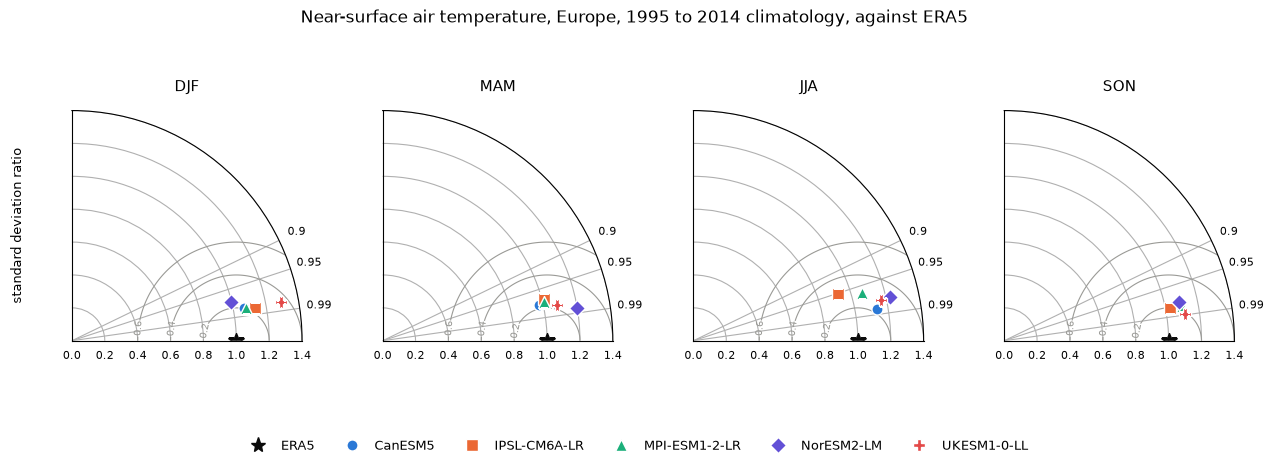

In [15]:
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "P"]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), subplot_kw={"projection": "polar"})
rmax = 1.4
for ax, season in zip(axes, ["DJF", "MAM", "JJA", "SON"], strict=True):
    ax.set_thetamin(0)
    ax.set_thetamax(90)
    ax.set_rlim(0, rmax)
    r_ticks = np.array([0.9, 0.95, 0.99])
    ax.set_thetagrids(np.degrees(np.arccos(r_ticks)), [f"{r:g}" for r in r_ticks], fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    # centred RMS difference contours around the reference point
    th, rr = np.meshgrid(np.linspace(0, np.pi / 2, 200), np.linspace(0, rmax, 200))
    crms = np.sqrt(1 + rr**2 - 2 * rr * np.cos(th))
    cs = ax.contour(th, rr, crms, levels=[0.2, 0.4, 0.6], colors="#9a9a96", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.1f")
    ax.plot(0, 1, marker="*", markersize=12, color="#0b0b0b", zorder=5)
    for i, model in enumerate(results):
        row = taylor.loc[(model, season)]
        ax.plot(
            np.arccos(row.pearson_r),
            row.std_ratio,
            marker=MARKERS[i],
            markersize=8,
            color=COLOURS[i],
            markeredgecolor="white",
            markeredgewidth=1.0,
            linestyle="none",
            label=model,
            zorder=6,
        )
    ax.set_title(season, pad=14, fontsize=11)
axes[0].set_ylabel("standard deviation ratio", labelpad=28, fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
handles.insert(0, plt.Line2D([], [], marker="*", color="#0b0b0b", linestyle="none", markersize=11))
labels.insert(0, "ERA5")
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle(
    "Near-surface air temperature, Europe, 1995 to 2014 climatology, against ERA5", fontsize=12
)
fig.subplots_adjust(bottom=0.2, top=0.82, wspace=0.35)
plt.show()

## Where the seasonal biases are

The `time` sample holds per-grid-point statistics over the time steps of each
group. Its `mean_bias` is the 20-year seasonal mean difference at each point,
here on each model's grid. The grey line is the ERA5 land-sea boundary on its
own 1.5 degree grid.

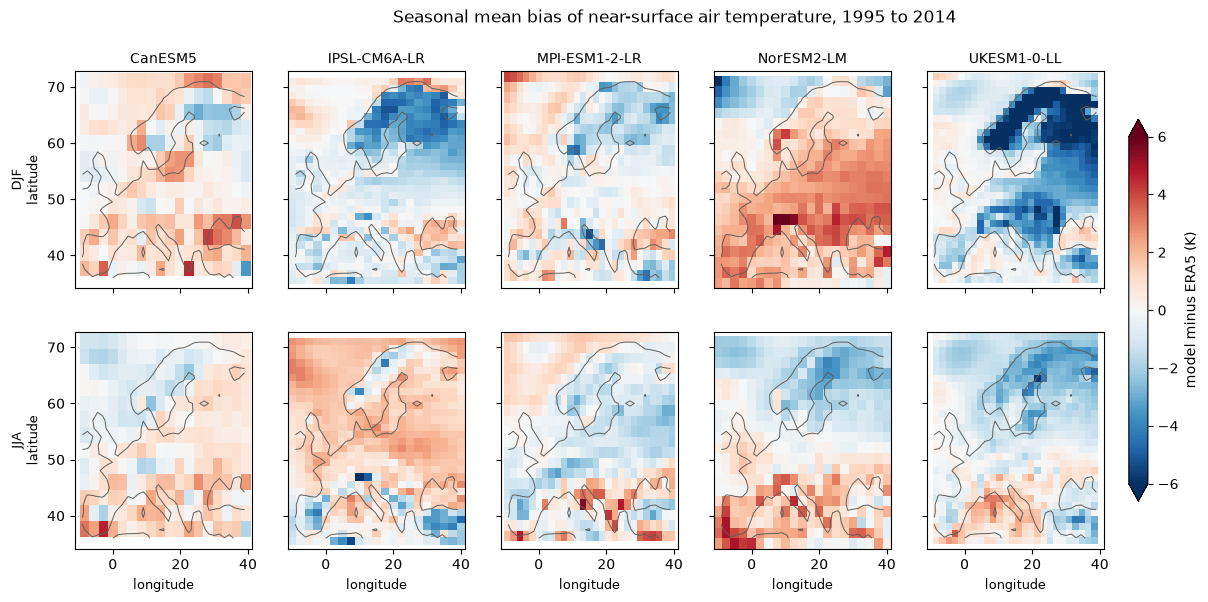

In [16]:
maps = {source: res.field("time")["mean_bias"] for source, res in results.items()}
lsm = era5["land_sea_mask"]
if "time" in lsm.dims:
    lsm = lsm.isel(time=0)
lsm = lsm.assign_coords(longitude=((lsm.longitude + 180) % 360) - 180).sortby("longitude")
lsm = (
    lsm.sel(latitude=slice(35, 72), longitude=slice(-10, 40))
    .load()
    .transpose("latitude", "longitude")
)

limit = 6.0
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2), sharex=True, sharey=True)
for row, season in enumerate(["DJF", "JJA"]):
    for col, model in enumerate(results):
        ax = axes[row, col]
        field = maps[model].sel(group=season)
        mesh = ax.pcolormesh(
            field.lon,
            field.lat,
            field.transpose("lat", "lon"),
            cmap="RdBu_r",
            vmin=-limit,
            vmax=limit,
            shading="nearest",
        )
        ax.contour(lsm.longitude, lsm.latitude, lsm, levels=[0.5], colors="#5f5e5a", linewidths=0.7)
        ax.set_aspect(1 / np.cos(np.deg2rad(53)))
        if row == 0:
            ax.set_title(model, fontsize=10)
        if col == 0:
            ax.set_ylabel(f"{season}\nlatitude", fontsize=9)
        if row == 1:
            ax.set_xlabel("longitude", fontsize=9)
cbar = fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.02, extend="both")
cbar.set_label("model minus ERA5 (K)")
fig.suptitle("Seasonal mean bias of near-surface air temperature, 1995 to 2014", fontsize=12)
plt.show()

In [17]:
over = pd.DataFrame(
    {
        source: {
            "grid points": m.sizes["lat"] * m.sizes["lon"],
            **{s: int((np.abs(m.sel(group=s)) > limit).sum()) for s in ["DJF", "JJA"]},
        }
        for source, m in maps.items()
    }
).T
print("Grid points beyond the colour scale of +-6 K:")
over

Grid points beyond the colour scale of +-6 K:


,grid points,DJF,JJA
CanESM5,234,0,0
IPSL-CM6A-LR,609,0,1
MPI-ESM1-2-LR,540,0,0
NorESM2-LM,420,3,0
UKESM1-0-LL,780,69,0


The maps have two kinds of structure: large areas of one sign, and
small-scale speckle along mountains and coasts, where a coarse model grid
and the 1.5 degree ERA5 grid resolve the terrain and the coastline
differently. To put a number on the large-scale part, the next cell averages
the seasonal bias maps over two sub-boxes of the region, the north-east (55N
to 72N, 10E to 40E) and the south (35N to 48N), weighted by cell area. The
cell areas come from climval's `cell_area`, with edges midway between
neighbouring grid points. On the Gaussian (unevenly spaced) latitudes of
CanESM5 and MPI-ESM1-2-LR these are close to the true cell areas (within
about 1% at the polar rows, much less at the latitudes used here); pass
`lat_bnds` or `area=` for exact areas.

In [18]:
from climval.align.weights import cell_area


def area_mean(field):
    area, _ = cell_area(field)
    return float(field.weighted(area).mean(["lat", "lon"]))


parts = {
    "north-east": dict(lat=slice(55, 72), lon=slice(10, 40)),
    "south": dict(lat=slice(35, 48)),
}
sub_means = pd.DataFrame(
    {
        (name, season): {
            source: area_mean(m.sel(group=season, **box).transpose("lat", "lon"))
            for source, m in maps.items()
        }
        for name, box in parts.items()
        for season in ["DJF", "JJA"]
    }
)
for (name, season), column in sub_means.items():
    cold = ", ".join(column[column < -1].index) or "none"
    warm = ", ".join(column[column > 1].index) or "none"
    print(
        f"{season} {name}: colder than ERA5 by more than 1 K: {cold}; "
        f"warmer by more than 1 K: {warm}"
    )
sub_means.round(2)

DJF north-east: colder than ERA5 by more than 1 K: IPSL-CM6A-LR, MPI-ESM1-2-LR, UKESM1-0-LL; warmer by more than 1 K: NorESM2-LM
JJA north-east: colder than ERA5 by more than 1 K: NorESM2-LM, UKESM1-0-LL; warmer by more than 1 K: IPSL-CM6A-LR
DJF south: colder than ERA5 by more than 1 K: UKESM1-0-LL; warmer by more than 1 K: CanESM5, NorESM2-LM
JJA south: colder than ERA5 by more than 1 K: none; warmer by more than 1 K: CanESM5, NorESM2-LM


north-east       south      
                     DJF   JJA   DJF   JJA
CanESM5             0.08  0.13  1.30  1.12
IPSL-CM6A-LR       -2.41  1.18 -0.34 -0.16
MPI-ESM1-2-LR      -1.08 -0.88  0.03  0.28
NorESM2-LM          1.18 -1.77  2.20  1.56
UKESM1-0-LL        -4.09 -2.19 -1.16  0.25

## Month by month

The `space_time` sample compares every month at every grid point. A free
running historical simulation is not synchronised with the observed weather,
so these numbers include internal variability and, here, the sampling noise
of the ERA5 monthly means. They are larger than the climatology numbers and
should not be read as model error alone.

In [19]:
st = values[(values["sample"] == "space_time") & (values["group"] == "all")]
st.pivot_table(index="model", columns="metric", values="value")[
    ["mean_bias", "rmse", "pearson_r"]
].round(3)

metric,mean_bias,rmse,pearson_r
model,,,
CanESM5,0.397,2.834,0.944
IPSL-CM6A-LR,-0.193,3.153,0.937
MPI-ESM1-2-LR,-0.255,3.061,0.936
NorESM2-LM,0.862,3.192,0.935
UKESM1-0-LL,-1.129,3.550,0.936


## Provenance and reports

Each result records the inputs, every alignment step and the software
versions. It exports to JSON, HTML and Markdown.

In [20]:
result = results["UKESM1-0-LL"]
prov = result.provenance
print("options:", prov["options"])
print("seasons:", prov["metric_notes"]["seasons"])
print("created", prov["created"])
env = prov["environment"]
print(
    "climval",
    env["climval"],
    "| python",
    env["python"],
    "|",
    ", ".join(
        f"{k} {env['libraries'][k]}"
        for k in ("xarray", "numpy", "dask", "zarr")
        if k in env["libraries"]
    ),
)

options: {'regrid': 'bilinear', 'target': 'candidate', 'time': 'intersect', 'freq': None, 'min_coverage': 0.8, 'period': ['1995', '2014'], 'units': 'convert', 'weights': 'area', 'region': {'type': 'box', 'name': 'Europe', 'lat': [35, 72], 'lon': [-10, 40], 'crosses_antimeridian': False}, 'by': 'season', 'seasons': 'contiguous', 'samples': ['space_time', 'climatology', 'time'], 'metrics': ['rmse', 'mae', 'mean_bias', 'nrmse', 'pearson_r', 'taylor_skill_score', 'percentile_bias_p95', 'percentile_bias_p5', 'crmse', 'std_ratio', 'kge']}
seasons: {'mode': 'contiguous', 'incomplete_seasons_left_out': ['DJF 1995', 'DJF 2015']}
created 2026-10-30T07:17:58+00:00
climval 0.2.0 | python 3.12.10 | xarray 2026.9.0, numpy 2.5.4, dask 2026.8.0, zarr 3.4.2


In [21]:
for source, res in results.items():
    res.export(f"output/era5_cmip6_europe_{source}.html")
    res.export(f"output/era5_cmip6_europe_{source}.json")
values.to_csv("output/era5_cmip6_europe_values.csv", index=False)
print("written to output/")

written to output/


## What the numbers show

- All five models reproduce the large-scale pattern of the seasonal
  climatology closely: the pattern correlations printed above are high in
  every season. A temperature field over Europe is dominated by the
  north-south gradient and the land-sea contrast, so a high pattern
  correlation of this kind says little about regional detail.
- The models differ more in their mean bias and their centred RMS
  difference. The summary after the table names the extremes of each.
- The bias maps show large areas of one sign, quantified for two sub-boxes
  in the table above, and small-scale speckle near mountains and coasts.
  This comparison does not adjust for the different orography of the
  grids, so the speckle should not be read as model error alone.
- Month by month (`space_time`), the RMS differences are larger than for
  the climatology, as expected for free-running simulations.

Limits of this comparison: one member per model; one reanalysis; ERA5
monthly means estimated from one sampled two-day block in six (standard
errors above); ERA5 interpolated bilinearly onto each model grid, which
samples ERA5 at the model points (conservative remapping through xESMF,
`regrid="conservative"`, would average the ERA5 cells instead); five
models on five grids, so the numbers of different models rest on different
sets of points; no orography
adjustment; a box that includes sea points. The numbers describe these five
simulations against ERA5 over this box and period, nothing more.

## Data and licences

**ERA5**: Hersbach et al. (2020), https://doi.org/10.1002/qj.3803, read from
ARCO-ERA5 (Carver and Merose 2023, https://github.com/google-research/arco-era5)
in Google Cloud public datasets. The Copernicus Climate Data Store
publishes ERA5 under the CC-BY licence, that is Creative Commons
Attribution 4.0 (https://creativecommons.org/licenses/by/4.0/; ERA5 hourly
data on single levels, https://doi.org/10.24381/cds.adbb2d47). Contains
modified Copernicus Climate Change Service information 2026: ARCO-ERA5
regridded the data to 1.5 degrees, and this notebook sampled them and
averaged them to monthly means. Neither the European Commission nor ECMWF
is responsible for any use that may be made of the Copernicus information
or data it contains.

**CMIP6**: Eyring et al. (2016), https://doi.org/10.5194/gmd-9-1937-2016,
read from the Pangeo CMIP6 collection on Google Cloud
(https://pangeo-data.github.io/pangeo-cmip6-cloud/). The model output is
used under CC BY 4.0. The files still carry the licence they were
published with, CC BY-SA 4.0 or CC BY-NC-SA 4.0 (column `licence in the
file` below), but between November 2021 and September 2022 the groups
behind these five models relaxed it to CC BY 4.0, as all CMIP6 modelling
groups did by October 2022: see the CMIP6 Terms of Use
(https://pcmdi.llnl.gov/CMIP6/TermsOfUse/TermsOfUse6-2.html) and the
per-model licence history in the CMIP6 controlled vocabularies
(https://wcrp-cmip.github.io/CMIP6_CVs/docs/CMIP6_source_id_licenses.html),
from which the column `relaxed to CC BY 4.0` is copied. We acknowledge the World Climate
Research Programme, which, through its Working Group on Coupled Modelling,
coordinated and promoted CMIP6, the climate modelling groups for producing
and making available their model output, the Earth System Grid Federation
(ESGF) for archiving the data and providing access, and the multiple funding
agencies who support CMIP6 and ESGF.

In [22]:
RELAXED = {
    "CanESM5": "2022-09-27",
    "IPSL-CM6A-LR": "2022-06-03",
    "MPI-ESM1-2-LR": "2022-06-16",
    "NorESM2-LM": "2022-06-03",
    "UKESM1-0-LL": "2021-11-15",
}
pd.DataFrame(
    {
        s: {
            "institution_id": ds.attrs.get("institution_id"),
            "institution": ds.attrs.get("institution"),
            "licence in the file": ds.attrs.get("license"),
            "relaxed to CC BY 4.0": RELAXED[s],
        }
        for s, ds in sorted((d.attrs["source_id"], d) for d in dsets.values())
    }
).T.style.set_uuid("licences").set_properties(**{"white-space": "normal", "text-align": "left"})

,institution_id,institution,licence in the file,relaxed to CC BY 4.0
CanESM5,CCCma,"Canadian Centre for Climate Modelling and Analysis, Environment and Climate Change Canada, Victoria, BC V8P 5C2, Canada","CMIP6 model data produced by The Government of Canada (Canadian Centre for Climate Modelling and Analysis, Environment and Climate Change Canada) is licensed under a Creative Commons Attribution ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and at https:///pcmdi.llnl.gov/. The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law.",2022-09-27
IPSL-CM6A-LR,IPSL,"Institut Pierre Simon Laplace, Paris 75252, France","CMIP6 model data produced by IPSL is licensed under a Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and at https://cmc.ipsl.fr/. The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law.",2022-06-03
MPI-ESM1-2-LR,MPI-M,"Max Planck Institute for Meteorology, Hamburg 20146, Germany","CMIP6 model data produced by MPI-M is licensed under a Creative Commons Attribution ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and. The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law.",2022-06-16
NorESM2-LM,NCC,"NorESM Climate modeling Consortium consisting of CICERO (Center for International Climate and Environmental Research, Oslo 0349), MET-Norway (Norwegian Meteorological Institute, Oslo 0313), NERSC (Nansen Environmental and Remote Sensing Center, Bergen 5006), NILU (Norwegian Institute for Air Research, Kjeller 2027), UiB (University of Bergen, Bergen 5007), UiO (University of Oslo, Oslo 0313) and UNI (Uni Research, Bergen 5008), Norway. Mailing address: NCC, c/o MET-Norway, Henrik Mohns plass 1, Oslo 0313, Norway","CMIP6 model data produced by NCC is licensed under a Creative Commons Attribution ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and at https:///pcm